# 04 — Topic Modelling per Kelas dan Dinamika Topik (BERTopic)

**Proyek:** Analisis Dinamika Topik Pemberitaan Generative AI pada Media Online Indonesia Menggunakan BERTopic

**Video penjelasan:** `<<TEMPEL LINK VIDEO DI SINI>>`

Notebook ini menjawab Task 4. Korpus dipisah menurut kelas hasil klasifikasi akhir (`pred_label`),
lalu **topic modelling dijalankan terpisah untuk tiap kelas**. Untuk tiap kelas kami: (1) menjelaskan
metode dan alasannya, (2) menentukan jumlah topik, (3) mengekstrak kata kunci, (4) memberi nama topik,
(5) menampilkan dokumen representatif, (6) memvisualisasikan distribusi topik, dan — sesuai judul
proyek — (7) menganalisis **dinamika topik dari waktu ke waktu**.

In [1]:
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error(); hf_logging.disable_progress_bar()
import copy, sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from bertopic import BERTopic
from bertopic.vectorizers import ClassTfidfTransformer
from gensim.corpora import Dictionary
from gensim.models import LdaModel
from gensim.models.coherencemodel import CoherenceModel
from hdbscan import HDBSCAN
from scipy.stats import chi2_contingency
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP

warnings.filterwarnings("ignore")
ROOT = Path.cwd()   # jalankan notebook dari folder repo
SCRAPED, RES, MODELS, FIG = ROOT / "scraped", ROOT / "results", ROOT / "models", ROOT / "figures"
for _d in (SCRAPED, RES, MODELS, FIG):
    _d.mkdir(exist_ok=True)
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

df = pd.read_csv(ROOT / "dataset_classified.csv", parse_dates=["date"])
df["desc"] = df["desc"].fillna("")
CLASSES = sorted(df["pred_label"].unique())
df["pred_label"].value_counts()

pred_label
Teknologi     2864
Nasional      1268
Ekonomi       1079
Hiburan        766
Pendidikan     737
Name: count, dtype: int64

## 1. Metode dan justifikasi

**Metode utama: BERTopic.** Alurnya: *sentence embedding* → reduksi dimensi (UMAP) → klasterisasi
kepadatan (HDBSCAN) → representasi topik dengan *class-based* TF-IDF (c-TF-IDF).

Alasan memilih BERTopic untuk korpus ini:

1. **Semua dokumen membahas AI.** Kosakata antar-topik sangat tumpang tindih (ai, teknologi, data,
   pengguna, ...). Model *bag-of-words* seperti LDA sulit memisahkan topik yang kosakatanya mirip;
   embedding kontekstual membedakan dokumen dari maknanya, bukan hanya dari kemunculan kata.
2. **Jumlah topik tidak perlu ditebak di awal.** HDBSCAN menemukan klaster dari kepadatan data, lalu
   jumlah topik akhir ditentukan secara terukur (bagian 3).
3. **Mendukung analisis dinamis.** `topics_over_time` menghitung ulang c-TF-IDF per periode di atas
   satu klasterisasi global, sehingga identitas topik stabil sepanjang waktu — inti dari judul proyek.

**Pembanding: LDA** (gensim) dilatih pada data dan jumlah topik yang sama, dievaluasi dengan metrik
yang sama, supaya pilihan metode didukung angka dan bukan hanya argumen.

**Dua masukan berbeda.** Embedding dihitung dari **teks alami** (judul + 3 paragraf pertama — berita
memakai piramida terbalik sehingga inti berita ada di awal, dan batas masukan model 512 token).
c-TF-IDF dan LDA memakai **token hasil preprocessing** (case folding, tanpa stopword, frasa dua kata
digabung dengan `_`) supaya kata kunci topik bersih dan mudah dibaca.

In [2]:
EMB_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
emb_path = MODELS / f"embeddings_minilm_{len(df)}.npy"
if emb_path.exists():
    EMB = np.load(emb_path)
else:
    st = SentenceTransformer(EMB_NAME, device=DEVICE)
    EMB = st.encode(df["embed_text"].tolist(), batch_size=64, show_progress_bar=True, normalize_embeddings=True)
    np.save(emb_path, EMB)
    del st; torch.cuda.empty_cache()
print("embedding:", EMB.shape)

embedding: (6714, 384)


## 2. Fungsi bantu: pelatihan dan metrik

- **Koherensi C_v dan NPMI** (10 kata teratas per topik): apakah kata-kata kunci sebuah topik memang
  sering muncul bersama di korpus. Makin tinggi makin koheren.
- **Topic diversity**: proporsi kata unik di antara 10 kata teratas semua topik. Mendekati 1 berarti
  topik-topik tidak saling mengulang.
- **Rasio outlier**: bagian dokumen yang tidak masuk klaster mana pun (topik −1) sebelum *outlier reduction*.

In [3]:
def make_vectorizer(docs_tok):
    """CountVectorizer untuk c-TF-IDF. Di BERTopic vectorizer ini dijalankan pada 'dokumen kelas'
    (gabungan semua dokumen satu topik), jadi min_df/max_df tidak bisa dipakai langsung. Kosakata
    disaring di level dokumen asli: kata harus muncul di >= 5 dokumen dan <= 60% dokumen."""
    cv = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False,
                         min_df=5, max_df=0.6).fit(docs_tok)
    return CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False,
                           vocabulary=cv.get_feature_names_out())


def fit_bertopic(docs_tok, emb, min_cluster_size, selection="eom"):
    model = BERTopic(
        embedding_model=None,
        # "multilingual": korpus berbahasa Indonesia, dan pada mode "english" BERTopic membuang
        # karakter "_" sehingga frasa seperti kecerdasan_buatan hilang dari kosakata c-TF-IDF
        language="multilingual",
        umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED),
        hdbscan_model=HDBSCAN(min_cluster_size=min_cluster_size, min_samples=5, metric="euclidean",
                              cluster_selection_method=selection, prediction_data=True),
        vectorizer_model=make_vectorizer(docs_tok),
        ctfidf_model=ClassTfidfTransformer(reduce_frequent_words=True),
        top_n_words=10, calculate_probabilities=False, verbose=False,
    )
    topics, _ = model.fit_transform(docs_tok, emb)
    return model, np.array(topics)


def top_words(model, n=10):
    return {t: [w for w, _ in model.get_topic(t)[:n]] for t in model.get_topics() if t != -1}


def quality(topic_words, tokens, dictionary):
    tw = [[w for w in ws if w in dictionary.token2id] for ws in topic_words]
    tw = [ws for ws in tw if len(ws) >= 3]
    out = {}
    for name in ("c_v", "c_npmi"):
        out[name] = CoherenceModel(topics=tw, texts=tokens, dictionary=dictionary, coherence=name,
                                   topn=10, processes=1).get_coherence()
    flat = [w for ws in topic_words for w in ws]
    out["diversity"] = len(set(flat)) / max(1, len(flat))
    return out


def fit_lda(tokens, dictionary, k):
    corpus = [dictionary.doc2bow(t) for t in tokens]
    lda = LdaModel(corpus, num_topics=k, id2word=dictionary, passes=10, random_state=SEED, alpha="auto", eta="auto")
    return [[w for w, _ in lda.show_topic(i, 10)] for i in range(k)]

## 3. Menentukan jumlah topik per kelas

Prosedur, diulang untuk setiap kelas:

1. Latih BERTopic dasar. `min_cluster_size` diskalakan dengan ukuran kelas (±1% dokumen, minimal 10)
   agar topik terkecil tetap punya cukup dokumen untuk diringkas.
   Bila HDBSCAN (`cluster_selection_method="eom"`) menghasilkan kurang dari 6 klaster, model dilatih
   ulang dengan `"leaf"` agar kelas kecil tidak tergabung menjadi satu topik raksasa.
2. Dari klaster halus tersebut, topik digabung bertahap (`reduce_topics`) ke **k = 4 … 12**. Untuk tiap
   k dihitung C_v, NPMI, dan diversity; LDA dilatih pada k yang sama sebagai pembanding. Bila HDBSCAN
   hanya menemukan kurang dari 4 klaster, semua klaster awal dipakai.
3. **k terpilih = k dengan skor C_v × diversity × keseimbangan tertinggi** pada BERTopic.
   - *C_v × diversity*: tidak memilih solusi yang koheren tetapi topiknya saling mengulang, dan sebaliknya.
   - *keseimbangan* = entropi ternormalisasi dari ukuran topik (1 = semua topik sama besar). Tanpa faktor
     ini, k kecil selalu menang karena penggabungan hierarkis menghasilkan satu **topik raksasa** yang
     menelan 80–90% dokumen kelas (kata kuncinya hanya kata umum seperti "digital", "data"); topik
     seperti itu tidak menjawab pertanyaan "tema apa saja yang dibahas" dan merusak ringkasan sadar-topik.

Rentang 4–12 dipilih karena tiap topik nantinya harus diwakili dalam ringkasan kelas (Task 5): terlalu
sedikit topik menyembunyikan tema, terlalu banyak membuat ringkasan tidak lagi ringkas.

In [4]:
K_RANGE = [4, 5, 6, 7, 8, 10, 12]
results, sweep_rows, base_info = {}, [], []

for cls in CLASSES:
    sub = df[df["pred_label"] == cls].reset_index(drop=True)
    emb = EMB[df.index[df["pred_label"] == cls]]
    docs_tok = sub["tokens"].tolist()
    tokens = [d.split() for d in docs_tok]
    dictionary = Dictionary(tokens)
    dictionary.filter_extremes(no_below=5, no_above=0.6)

    mcs = max(10, int(0.01 * len(sub)))
    cache = MODELS / f"bertopic_base_{cls}_{len(sub)}.pkl"
    if cache.exists():
        base = BERTopic.load(str(cache)); base_topics = np.array(base.topics_)
    else:
        base, base_topics = fit_bertopic(docs_tok, emb, mcs)
        if len(set(base_topics) - {-1}) < 6:
            # "eom" cenderung menyatukan kelas kecil menjadi satu klaster raksasa; "leaf" memilih
            # klaster-klaster daun yang lebih halus sehingga sub-tema tetap terpisah
            base, base_topics = fit_bertopic(docs_tok, emb, mcs, selection="leaf")
        base.save(str(cache), serialization="pickle", save_embedding_model=False)
    n_base = len(set(base_topics)) - (1 if -1 in base_topics else 0)
    base_info.append({"kelas": cls, "dokumen": len(sub), "min_cluster_size": mcs, "topik_awal": n_base,
                      "rasio_outlier": round(float((base_topics == -1).mean()), 3)})

    best = None
    for k in ([k for k in K_RANGE if k <= n_base] or [n_base]):   # kelas kecil: pakai semua topik awal
        m = copy.deepcopy(base)
        if k < n_base:
            m.reduce_topics(docs_tok, nr_topics=k + 1)      # +1: topik outlier (-1) ikut dihitung BERTopic
        tw = top_words(m)
        qb = quality(list(tw.values()), tokens, dictionary)
        ql = quality(fit_lda(tokens, dictionary, len(tw)), tokens, dictionary)
        tt = np.array(m.topics_); share = pd.Series(tt[tt != -1]).value_counts(normalize=True)
        balance = float(-(share * np.log(share)).sum() / np.log(len(share))) if len(share) > 1 else 0.0
        score = qb["c_v"] * qb["diversity"] * balance
        sweep_rows.append({"kelas": cls, "k": len(tw), **{f"bertopic_{a}": b for a, b in qb.items()},
                           "bertopic_balance": balance, "porsi_topik_terbesar": float(share.max()), "skor": score,
                           **{f"lda_{a}": b for a, b in ql.items()}})
        if best is None or score > best[0]:
            best = (score, len(tw), m)
    results[cls] = {"sub": sub, "emb": emb, "docs_tok": docs_tok, "tokens": tokens, "dictionary": dictionary,
                    "model": best[2], "k": best[1]}
    print(f"{cls}: {len(sub)} dok, topik awal {n_base}, k terpilih = {best[1]}")

sweep = pd.DataFrame(sweep_rows)
sweep.to_csv(RES / "topic_k_sweep.csv", index=False)
pd.DataFrame(base_info)

Ekonomi: 1079 dok, topik awal 30, k terpilih = 12


Hiburan: 766 dok, topik awal 19, k terpilih = 12


Nasional: 1268 dok, topik awal 26, k terpilih = 12


Pendidikan: 737 dok, topik awal 17, k terpilih = 10


Teknologi: 2864 dok, topik awal 28, k terpilih = 12


,kelas,dokumen,min_cluster_size,topik_awal,rasio_outlier
0,Ekonomi,1079,10,30,0.330
1,Hiburan,766,10,19,0.219
2,Nasional,1268,12,26,0.197
3,Pendidikan,737,10,17,0.252
4,Teknologi,2864,28,28,0.194


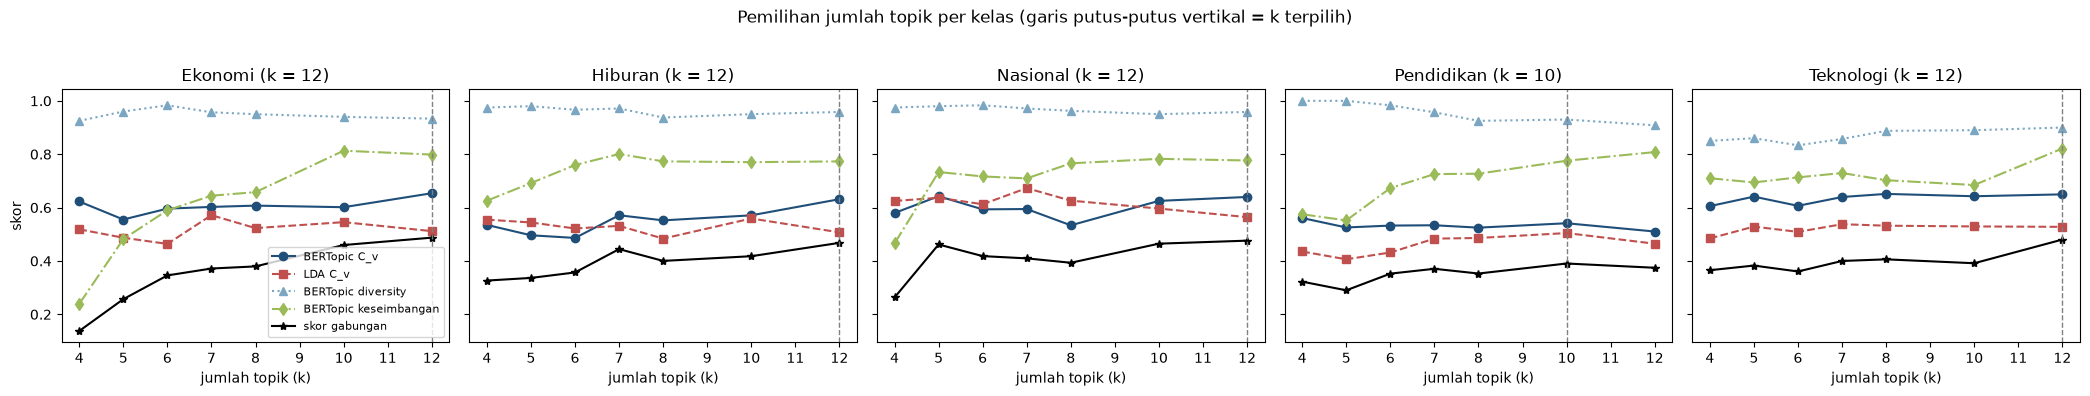

In [5]:
fig, axes = plt.subplots(1, len(CLASSES), figsize=(4.2 * len(CLASSES), 3.8), sharey=True)
for ax, cls in zip(axes, CLASSES):
    s = sweep[sweep.kelas == cls]
    ax.plot(s.k, s.bertopic_c_v, "o-", label="BERTopic C_v", color="#1f4e79")
    ax.plot(s.k, s.lda_c_v, "s--", label="LDA C_v", color="#c0504d")
    ax.plot(s.k, s.bertopic_diversity, "^:", label="BERTopic diversity", color="#7aa6c2")
    ax.plot(s.k, s.bertopic_balance, "d-.", label="BERTopic keseimbangan", color="#9bbb59")
    ax.plot(s.k, s.skor, "*-", label="skor gabungan", color="black")
    ax.axvline(results[cls]["k"], color="gray", lw=1, ls="--")
    ax.set_title(f"{cls} (k = {results[cls]['k']})"); ax.set_xlabel("jumlah topik (k)")
axes[0].set_ylabel("skor"); axes[0].legend(fontsize=8)
plt.suptitle("Pemilihan jumlah topik per kelas (garis putus-putus vertikal = k terpilih)", y=1.03)
plt.tight_layout(); plt.savefig(FIG / "04_k_selection.png", dpi=150, bbox_inches="tight"); plt.show()

In [6]:
chosen = pd.concat([sweep[(sweep.kelas == c) & (sweep.k == results[c]["k"])] for c in CLASSES])
chosen.to_csv(RES / "topic_quality_chosen.csv", index=False)
print("Rata-rata lintas kelas pada k terpilih:")
print(chosen.drop(columns=["kelas", "k"]).mean().round(3).to_string())
chosen.set_index("kelas").round(3)

Rata-rata lintas kelas pada k terpilih:
bertopic_c_v            0.623
bertopic_c_npmi         0.059
bertopic_diversity      0.936
bertopic_balance        0.789
porsi_topik_terbesar    0.335
skor                    0.460
lda_c_v                 0.523
lda_c_npmi              0.026
lda_diversity           0.710


,k,bertopic_c_v,bertopic_c_npmi,bertopic_diversity,bertopic_balance,porsi_topik_terbesar,skor,lda_c_v,lda_c_npmi,lda_diversity
kelas,,,,,,,,,,
Ekonomi,12,0.654,0.054,0.933,0.799,0.322,0.487,0.512,0.042,0.675
Hiburan,12,0.632,0.065,0.958,0.773,0.316,0.468,0.507,0.002,0.783
Nasional,12,0.640,0.062,0.958,0.777,0.290,0.476,0.564,0.028,0.692
Pendidikan,10,0.541,0.022,0.930,0.776,0.405,0.391,0.505,0.040,0.660
Teknologi,12,0.650,0.094,0.900,0.821,0.342,0.480,0.528,0.019,0.742


**Interpretasi pemilihan jumlah topik dan perbandingan dengan LDA.** Jumlah topik terpilih: Ekonomi,
Hiburan, Nasional, Teknologi masing-masing 12 dan Pendidikan 10 (total 58 topik). Pada k terpilih,
BERTopic mengungguli LDA di **semua kelas** untuk koherensi C_v (rata-rata 0,623 vs 0,523) dan topic
diversity (0,936 vs 0,710), serta di empat dari lima kelas untuk NPMI (rata-rata 0,059 vs 0,026;
pengecualiannya Pendidikan, keduanya mendekati nol). Diversity LDA yang rendah berarti banyak topik LDA
berbagi kata umum yang sama ("teknologi", "digital", "data") — persis masalah yang diperkirakan untuk korpus
yang seluruhnya membahas AI. Embedding membuat BERTopic membedakan dokumen dari maknanya, sehingga topik
seperti "Microsoft Copilot" dan "Fitur Meta AI di WhatsApp" terpisah walaupun kosakatanya mirip.

Faktor keseimbangan bekerja sesuai tujuan: tanpa faktor ini, percobaan awal memilih k kecil dengan satu
topik raksasa yang menelan 80–90% dokumen; dengan faktor ini porsi topik terbesar turun menjadi 29–41%.
Grafik di atas juga menunjukkan C_v BERTopic relatif datar terhadap k, sehingga memilih k yang lebih besar
tidak mengorbankan koherensi.

Rasio outlier HDBSCAN 19–33% wajar untuk berita: banyak artikel membahas AI secara umum tanpa sub-tema
yang padat. Outlier dipindahkan ke topik terdekat supaya setiap dokumen ikut dihitung dalam dinamika
dan ringkasan.

## 4. Outlier reduction dan penetapan topik akhir

HDBSCAN memberi label −1 pada dokumen di wilayah berkepadatan rendah. Agar setiap dokumen punya topik
(dibutuhkan untuk distribusi topik, analisis dinamis, dan ringkasan), dokumen outlier dipindahkan ke
topik yang **embedding-nya paling mirip**; representasi c-TF-IDF kemudian dihitung ulang.

In [7]:
doc_rows = []
for cls in CLASSES:
    R = results[cls]
    m, sub = R["model"], R["sub"]
    topics = list(m.topics_)
    if -1 in topics:
        topics = m.reduce_outliers(R["docs_tok"], topics, strategy="embeddings", embeddings=R["emb"])
        m.update_topics(R["docs_tok"], topics=topics, vectorizer_model=make_vectorizer(R["docs_tok"]),
                        ctfidf_model=ClassTfidfTransformer(reduce_frequent_words=True), top_n_words=10)
    R["topics"] = np.array(topics)
    # jarak ke pusat topik (centroid embedding) -> dipakai memilih dokumen representatif
    cent = {t: R["emb"][R["topics"] == t].mean(0) for t in sorted(set(topics))}
    R["centroids"] = {t: c / np.linalg.norm(c) for t, c in cent.items()}
    sim = np.array([R["emb"][i] @ R["centroids"][t] for i, t in enumerate(topics)])
    doc_rows.append(sub[["doc_id"]].assign(pred_label=cls, topic=topics, topic_sim=sim))
doc_topics = pd.concat(doc_rows, ignore_index=True)
doc_topics.groupby("pred_label")["topic"].nunique()

2026-11-11 21:49:37,213 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


2026-11-11 21:49:37,380 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


2026-11-11 21:49:37,562 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


2026-11-11 21:49:37,711 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


2026-11-11 21:49:38,013 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


pred_label
Ekonomi       12
Hiburan       12
Nasional      12
Pendidikan    10
Teknologi     12
Name: topic, dtype: int64

## 5. Kata kunci, nama topik, dan dokumen representatif

Kata kunci = 10 kata dengan skor c-TF-IDF tertinggi. Dokumen representatif = dokumen yang embedding-nya
paling dekat dengan pusat topik. **Nama topik diberikan secara manual** oleh peneliti setelah membaca
kata kunci dan judul dokumen representatif (lihat `TOPIC_NAMES`), karena nama yang bermakna menuntut
penilaian manusia atas isi berita.

In [8]:
# Nama topik diberikan manual oleh peneliti setelah membaca 10 kata kunci c-TF-IDF dan
# judul dokumen-dokumen yang paling dekat ke pusat topik. Kunci: (kelas, nomor topik)
TOPIC_NAMES = {
    # ---------------- Ekonomi
    ("Ekonomi", 0): "Transformasi digital & adopsi AI nasional",
    ("Ekonomi", 1): "Dampak AI pada pekerjaan & ekonomi",
    ("Ekonomi", 2): "PHK massal akibat AI",
    ("Ekonomi", 3): "Saham, IPO & valuasi perusahaan AI",
    ("Ekonomi", 4): "Bisnis OpenAI & Sam Altman",
    ("Ekonomi", 5): "AI dan kripto/Bitcoin",
    ("Ekonomi", 6): "Penipuan keuangan pakai deepfake",
    ("Ekonomi", 7): "Bisnis & utang AI Elon Musk",
    ("Ekonomi", 8): "Kemunculan DeepSeek & AI China",
    ("Ekonomi", 9): "AI di Bea Cukai",
    ("Ekonomi", 10): "Investasi SoftBank di OpenAI",
    ("Ekonomi", 11): "PHK Amazon demi investasi AI",
    # ---------------- Hiburan
    ("Hiburan", 0): "AI di industri film & kreatif",
    ("Hiburan", 1): "Tren prompt Gemini untuk edit foto",
    ("Hiburan", 2): "AI di industri musik",
    ("Hiburan", 3): "AI, anak-anak & kehidupan sehari-hari",
    ("Hiburan", 4): "Asmara & pernikahan dengan AI",
    ("Hiburan", 5): "Selebritas Korea & konten palsu AI",
    ("Hiburan", 6): "AI dalam budaya, seni & pariwisata",
    ("Hiburan", 7): "Aktris AI Tilly Norwood",
    ("Hiburan", 8): "Deepfake idol K-pop",
    ("Hiburan", 9): "AI di industri kecantikan",
    ("Hiburan", 10): "Tips ChatGPT untuk karier & hidup",
    ("Hiburan", 11): "Taylor Swift & penyalahgunaan AI",
    # ---------------- Nasional
    ("Nasional", 0): "Kebijakan AI & pendidikan digital nasional",
    ("Nasional", 1): "Kriminal: rekayasa foto & penipuan deepfake",
    ("Nasional", 2): "Tren prompt Gemini (miniatur, polaroid)",
    ("Nasional", 3): "AI untuk kemacetan Jakarta & pusat data Jatiluhur",
    ("Nasional", 4): "ChatGPT, curhat & kesehatan mental",
    ("Nasional", 5): "Kasus deepfake mahasiswa Untan",
    ("Nasional", 6): "AI, pers & jurnalisme",
    ("Nasional", 7): "Pejabat & tokoh mendorong AI (santri, pesantren)",
    ("Nasional", 8): "Video AI 'umrah ke Candi Borobudur'",
    ("Nasional", 9): "Cara memakai Meta AI di WhatsApp",
    ("Nasional", 10): "Mengenal deepfake & bahayanya",
    ("Nasional", 11): "AI di kepolisian (Polri)",
    # ---------------- Pendidikan
    ("Pendidikan", 0): "AI di perkuliahan, riset & dunia kerja",
    ("Pendidikan", 1): "Koding & AI di kurikulum sekolah",
    ("Pendidikan", 2): "ChatGPT di dunia akademik",
    ("Pendidikan", 3): "AI untuk riset & analisis data",
    ("Pendidikan", 4): "Pelatihan AI praktis (AI agent, website)",
    ("Pendidikan", 5): "Pendidikan AI di China",
    ("Pendidikan", 6): "Olimpiade, kompetisi & prodi AI",
    ("Pendidikan", 7): "Inovasi aplikasi AI mahasiswa & dosen",
    ("Pendidikan", 8): "Kelas & kursus AI daring",
    ("Pendidikan", 9): "Prompt Gemini untuk foto wisuda & CV",
    # ---------------- Teknologi
    ("Teknologi", 0): "Kebijakan, industri & dampak AI",
    ("Teknologi", 1): "Ponsel & laptop AI (Samsung, Asus)",
    ("Teknologi", 2): "ChatGPT & OpenAI",
    ("Teknologi", 3): "Deepfake, penipuan & keamanan siber",
    ("Teknologi", 4): "Google Gemini & Bard",
    ("Teknologi", 5): "Persaingan chip & memori AI (Nvidia)",
    ("Teknologi", 6): "Meta AI & ambisi Zuckerberg",
    ("Teknologi", 7): "Elon Musk, xAI & gugatan ke OpenAI",
    ("Teknologi", 8): "Microsoft Copilot",
    ("Teknologi", 9): "Fitur Meta AI di WhatsApp",
    ("Teknologi", 10): "AI di YouTube, musik & kreator",
    ("Teknologi", 11): "AI di militer & perang",
}

In [9]:
info_rows = []
for cls in CLASSES:
    R = results[cls]
    sub = R["sub"].assign(topic=R["topics"], sim=doc_topics[doc_topics.pred_label == cls]["topic_sim"].values)
    for t in sorted(set(R["topics"])):
        d = sub[sub.topic == t].sort_values("sim", ascending=False)
        info_rows.append({
            "kelas": cls, "topik": t, "nama": TOPIC_NAMES.get((cls, t), f"Topik {t}"),
            "jumlah_dok": len(d), "proporsi": round(len(d) / len(sub), 3),
            "kata_kunci": ", ".join(w for w, _ in R["model"].get_topic(t)[:10]),
            "dok_representatif": " | ".join(d["title"].head(3)),
            "url_representatif": " | ".join(d["url"].head(3)),
        })
topic_info = pd.DataFrame(info_rows)
topic_info.to_csv(ROOT / "topic_info.csv", index=False, encoding="utf-8-sig")
doc_topics = doc_topics.merge(topic_info[["kelas", "topik", "nama"]].rename(
    columns={"kelas": "pred_label", "topik": "topic", "nama": "topic_name"}), on=["pred_label", "topic"])
doc_topics.to_csv(RES / "doc_topics.csv", index=False)
np.save(MODELS / "topic_centroids.npy", {(c, t): v for c in CLASSES for t, v in results[c]["centroids"].items()},
        allow_pickle=True)

pd.set_option("display.max_colwidth", 200)
for cls in CLASSES:
    print(f"\n=== {cls.upper()} ===")
    display(topic_info[topic_info.kelas == cls][["topik", "nama", "jumlah_dok", "proporsi", "kata_kunci"]])


=== EKONOMI ===


,topik,nama,jumlah_dok,proporsi,kata_kunci
0,0,Transformasi digital & adopsi AI nasional,389,0.361,"digital, telkom, nasional, pemerintah, industri, data, pengembangan, kolaborasi, umkm, inovasi"
1,1,Dampak AI pada pekerjaan & ekonomi,323,0.299,"pekerjaan, manusia, kekayaan, membantu, bisnis, negara, miliarder, besar, dunia, data"
2,2,PHK massal akibat AI,73,0.068,"karyawan, phk, pekerjaan, meta, pekerja, pemutusan_hubungan, microsoft, tenaga_kerja, kerja_phk, kerja"
3,3,"Saham, IPO & valuasi perusahaan AI",61,0.057,"saham, ipo, nvidia, investor, indeks, saham_nvidia, anthropic, pendapatan, turun, kapitalisasi_pasar"
4,4,Bisnis OpenAI & Sam Altman,48,0.044,"chatgpt, openai, altman, microsoft, sam_altman, nirlaba, menghasilkan_uang, paypal, golden_visa, ceo_openai"
5,5,AI dan kripto/Bitcoin,44,0.041,"bitcoin, kripto, harga_bitcoin, penambangan, token, harga, skenario, aset_kripto, aset_digital, penambang_bitcoin"
6,6,Penipuan keuangan pakai deepfake,46,0.043,"penipuan, deepfake, korban, palsu, satgas, ojk, scam, penipu, sri_mulyani, suara"
7,7,Bisnis & utang AI Elon Musk,27,0.025,"musk, elon_musk, xai, tesla, spacex, openai, mobil, utang, grok, tawaran"
8,8,Kemunculan DeepSeek & AI China,20,0.019,"deepseek, china, model, alibaba, liang, baidu, deepseek-v, buffett, tiongkok, liang_wenfeng"
9,9,AI di Bea Cukai,22,0.020,"bea_cukai, purbaya, peti_kemas, ekspor, alat_pemindai, direktorat_jenderal, dsi, pelabuhan_tanjung, djbc, sistem"



=== HIBURAN ===


,topik,nama,jumlah_dok,proporsi,kata_kunci
12,0,AI di industri film & kreatif,270,0.352,"film, aktor, grok, manusia, model, penggunaan, iklan, produksi, china, industri"
13,1,Tren prompt Gemini untuk edit foto,191,0.249,"prompt, gemini, detail, latar_belakang, pencahayaan, gaya, hasil, realistis, suasana, gambar"
14,2,AI di industri musik,49,0.064,"lagu, musik, musisi, spotify, suno, band, lagu-lagu, lirik, suara, karya"
15,3,"AI, anak-anak & kehidupan sehari-hari",65,0.085,"anak, manusia, pekerjaan, kesehatan, anak-anak, membantu, kemampuan, belajar, penelitian, tua"
16,4,Asmara & pernikahan dengan AI,42,0.055,"pernikahan, chatgpt, menikah, pria, wanita, suaminya, pengantin, hubungan, jiang, suami"
17,5,Selebritas Korea & konten palsu AI,32,0.042,"kim, hyun, min, woo, lee, jin, ayu, korea, netizen, chan"
18,6,"AI dalam budaya, seni & pariwisata",33,0.043,"pariwisata, wisatawan, pahlawan, perjuangan, perjalanan, desain, kawasan, semangat, bingkai, sektor"
19,7,Aktris AI Tilly Norwood,20,0.026,"tilly, tilly_norwood, aktris, particle, eline_van, aktor, der_velden, van_der, velden, eline"
20,8,Deepfake idol K-pop,18,0.023,"deepfake, entertainment, agensi, korban, blockchain, ador, artis, penyebaran_konten, kpop, italia"
21,9,AI di industri kecantikan,19,0.025,"kulit, kecantikan, skincare, beauty, wardah, perawatan, skin, clinic, analisis, produk"



=== NASIONAL ===


,topik,nama,jumlah_dok,proporsi,kata_kunci
24,0,Kebijakan AI & pendidikan digital nasional,417,0.329,"teknologi, pendidikan, digital, guru, manusia, mahasiswa, pembelajaran, siswa, penggunaan, artificial_intelligence"
25,1,Kriminal: rekayasa foto & penipuan deepfake,330,0.260,"korban, pelaku, tersangka, polisi, chiko, kasus, akun, deepfake, laporan, diduga"
26,2,"Tren prompt Gemini (miniatur, polaroid)",164,0.129,"prompt, gemini, latar_belakang, gambar, gaya, miniatur, hitam, polaroid, studio, edit"
27,3,AI untuk kemacetan Jakarta & pusat data Jatiluhur,109,0.086,"jalan, kemacetan, proyek, lintas, air, simpang, pusat_data, sistem, amdal, titik"
28,4,"ChatGPT, curhat & kesehatan mental",45,0.035,"chatgpt, chatbot, pengguna, openai, tulisan, character, percakapan, tools, altman, manusia"
29,5,Kasus deepfake mahasiswa Untan,34,0.027,"untan, satgas_ppkpt, sanksi, korban, teman, mahasiswa, deepfake_vulgar, satgas, perkuliahan, fmipa"
30,6,"AI, pers & jurnalisme",37,0.029,"karya_jurnalistik, pers, media, hak_cipta, jurnalistik, jurnalis, royalti, jurnalisme, dewan_pers, berita"
31,7,"Pejabat & tokoh mendorong AI (santri, pesantren)",49,0.039,"megawati, golden_visa, bingkai, pdip, tni, negara, investasi, visa, imigrasi, silmy"
32,8,Video AI 'umrah ke Candi Borobudur',26,0.021,"candi_borobudur, polresta_magelang, ode, borobudur, magelang, saksi, umrah, kemenyan, disparpora, mulyanto"
33,9,Cara memakai Meta AI di WhatsApp,18,0.014,"meta, whatsapp, meta_whatsapp, fitur, obrolan, pengguna, cara, mengaktifkan, berikut, pesan"



=== PENDIDIKAN ===


,topik,nama,jumlah_dok,proporsi,kata_kunci
36,0,"AI di perkuliahan, riset & dunia kerja",297,0.403,"pekerjaan, manusia, bidang, perusahaan, penggunaan, data, sistem, peneliti, kemampuan, mahasiswa"
37,1,Koding & AI di kurikulum sekolah,169,0.229,"mata_pelajaran, pendidikan, kemendikdasmen, coding, guru, koding, program, pembelajaran, sekolah, kurikulum"
38,2,ChatGPT di dunia akademik,74,0.100,"chatgpt, chatbot, openai, pengguna, mahasiswa, manusia, jawaban, gpt, tulisan, alat"
39,3,AI untuk riset & analisis data,46,0.062,"workshop, penelitian, riset, analisis, research, data, metodologi_penelitian, machine_learning, online_zoom, tesis"
40,4,"Pelatihan AI praktis (AI agent, website)",38,0.052,"website, kelas, bikin, project, profesional, marketing, konten, jam, langsung, mastery"
41,5,Pendidikan AI di China,24,0.033,"china, beijing, bahasa_inggris, jurusan, rencana, pendidikan, universitas, satelit, sekolah, sekolah_dasar"
42,6,"Olimpiade, kompetisi & prodi AI",37,0.050,"osn, prodi, seleksi, peserta, olimpiade, ambassador, kompetisi, google_student, kecerdasan_artifisial, ioai"
43,7,Inovasi aplikasi AI mahasiswa & dosen,26,0.035,"its, ugm, smart, film, pasien, sistem, situs, kesehatan, drone, tim"
44,8,Kelas & kursus AI daring,14,0.019,"kelas, peserta, peserta_terbaik, episode, wira, materi, lead, streamlit, investasi, sesi"
45,9,Prompt Gemini untuk foto wisuda & CV,12,0.016,"superkomputer, gemini, rambut, edit, putih, rapi, formal, studio, natural, pakaian"



=== TEKNOLOGI ===


,topik,nama,jumlah_dok,proporsi,kata_kunci
46,0,"Kebijakan, industri & dampak AI",1047,0.366,"apple, manusia, perusahaan, pengembangan, digital, data, kecerdasan_buatan, industri, bisnis, solusi"
47,1,"Ponsel & laptop AI (Samsung, Asus)",354,0.124,"samsung, galaxy, fitur, laptop, layar, perangkat, kamera, asus, ponsel, smartphone"
48,2,ChatGPT & OpenAI,299,0.104,"chatgpt, openai, gpt, chatbot, pengguna, percakapan, iklan, model, layanan, perusahaan"
49,3,"Deepfake, penipuan & keamanan siber",313,0.109,"deepseek, deepfake, keamanan, keamanan_siber, penipuan, palsu, serangan, grok, ancaman, korban"
50,4,Google Gemini & Bard,226,0.079,"google, gemini, bard, bing, pengguna, gmail, fitur, android, google_gemini, mesin_pencari"
51,5,Persaingan chip & memori AI (Nvidia),213,0.074,"nvidia, chip, china, intel, gpu, amd, memori, ram, huang, harga"
52,6,Meta AI & ambisi Zuckerberg,105,0.037,"meta, zuckerberg, muse, llama, mark_zuckerberg, wang, instagram, scale, facebook, facebook_instagram"
53,7,"Elon Musk, xAI & gugatan ke OpenAI",98,0.034,"musk, elon_musk, xai, grok, spacex, openai, altman, gugatan, tesla, twitter"
54,8,Microsoft Copilot,59,0.021,"copilot, microsoft, windows, microsoft_copilot, surface, notepad, aplikasi, fitur, pengguna, copilot_windows"
55,9,Fitur Meta AI di WhatsApp,41,0.014,"whatsapp, meta, stiker, fitur, meta_whatsapp, obrolan, whatsapp_business, chat, wabetainfo, pengguna"


In [10]:
for cls in CLASSES:
    print(f"\n=== {cls.upper()} — 3 dokumen paling representatif per topik ===")
    for _, r in topic_info[topic_info.kelas == cls].iterrows():
        print(f"\n[{r.topik}] {r.nama}  ({r.jumlah_dok} dok)")
        for title in r.dok_representatif.split(" | "):
            print("   •", title)


=== EKONOMI — 3 dokumen paling representatif per topik ===

[0] Transformasi digital & adopsi AI nasional  (389 dok)
   • Infomedia Pacu Transformasi Digital dengan Solusi Bisnis Berbasis AI
   • Telkom Luncurkan AIcosystem, Perkuat Adopsi AI untuk Berbagai Industri di Indonesia
   • AI Buka Peluang Kerja, Indonesia Perlu Perkuat Keahlian Digital

[1] Dampak AI pada pekerjaan & ekonomi  (323 dok)
   • HashMicro Bagikan Strategi Implementasi AI Efektif bagi Perusahaan
   • Peraih Nobel Ekonomi Ungkap Ancaman AI bagi Pekerja
   • AI Bisa Jadi Penggerak Mesin Pertumbuhan Ekonomi RI

[2] PHK massal akibat AI  (73 dok)
   • AI Picu PHK Massal, Lebih dari 50 Ribu Orang Kehilangan Pekerjaan di 2025
   • Banyak Perusahaan Mau PHK Massal Karyawan Gegara AI
   • Siap-siap, 41 Persen Perusahaan Bakal PHK Karyawan Imbas AI pada 2030

[3] Saham, IPO & valuasi perusahaan AI  (61 dok)
   • Bakal IPO, Pendapatan Anthropic Berpotensi Tembus Rp 3.565 Triliun
   • AI China DeepSeek Pukul Saham Teknologi

**Interpretasi topik per kelas — tema apa yang dibahas?**

- **Teknologi**: satu topik besar *Kebijakan, industri & dampak AI* (37%), lalu topik-topik **per
  perusahaan/produk**: ponsel dan laptop AI (Samsung, Asus), ChatGPT/OpenAI, Google Gemini, chip Nvidia,
  Meta, Elon Musk/xAI, Microsoft Copilot, fitur AI di WhatsApp, serta topik *Deepfake, penipuan & keamanan
  siber* dan *AI di militer & perang*. Berita teknologi AI di Indonesia sangat berorientasi pada produk
  dan perusahaan global.
- **Nasional**: kebijakan AI dan pendidikan digital oleh pemerintah, **kriminal rekayasa foto & penipuan
  deepfake**, tren *prompt* Gemini, serta peristiwa lokal yang sangat spesifik: AI untuk kemacetan Jakarta
  dan polemik pusat data AI Jatiluhur, kasus deepfake mahasiswa Untan, dan video AI "umrah ke Candi
  Borobudur". Ada juga topik tentang AI dan pers/jurnalisme.
- **Ekonomi**: transformasi digital BUMN, dampak AI pada pekerjaan dan PHK massal (termasuk PHK Amazon),
  pasar saham dan IPO perusahaan AI, AI dan kripto, penipuan keuangan dengan deepfake, serta bisnis OpenAI,
  Elon Musk, SoftBank, dan DeepSeek.
- **Pendidikan**: AI di perkuliahan dan dunia kerja, koding & AI di kurikulum sekolah, ChatGPT di dunia
  akademik, AI untuk riset, kompetisi dan prodi AI, pendidikan AI di China, serta kelas/kursus AI.
- **Hiburan**: AI di film dan industri kreatif, tren *prompt* Gemini untuk edit foto, musik AI, asmara dan
  pernikahan dengan AI, aktris AI Tilly Norwood, deepfake idol K-pop, dan selebritas yang jadi korban
  konten palsu.

Satu temuan menarik: tren *prompt* Gemini muncul di **tiga kelas** sekaligus (Hiburan, Nasional, dan
Pendidikan untuk foto wisuda/CV). Tren yang viral di media sosial ternyata diliput oleh banyak rubrik
sekaligus, masing-masing dengan sudut pandangnya sendiri.

## 6. Visualisasi distribusi topik

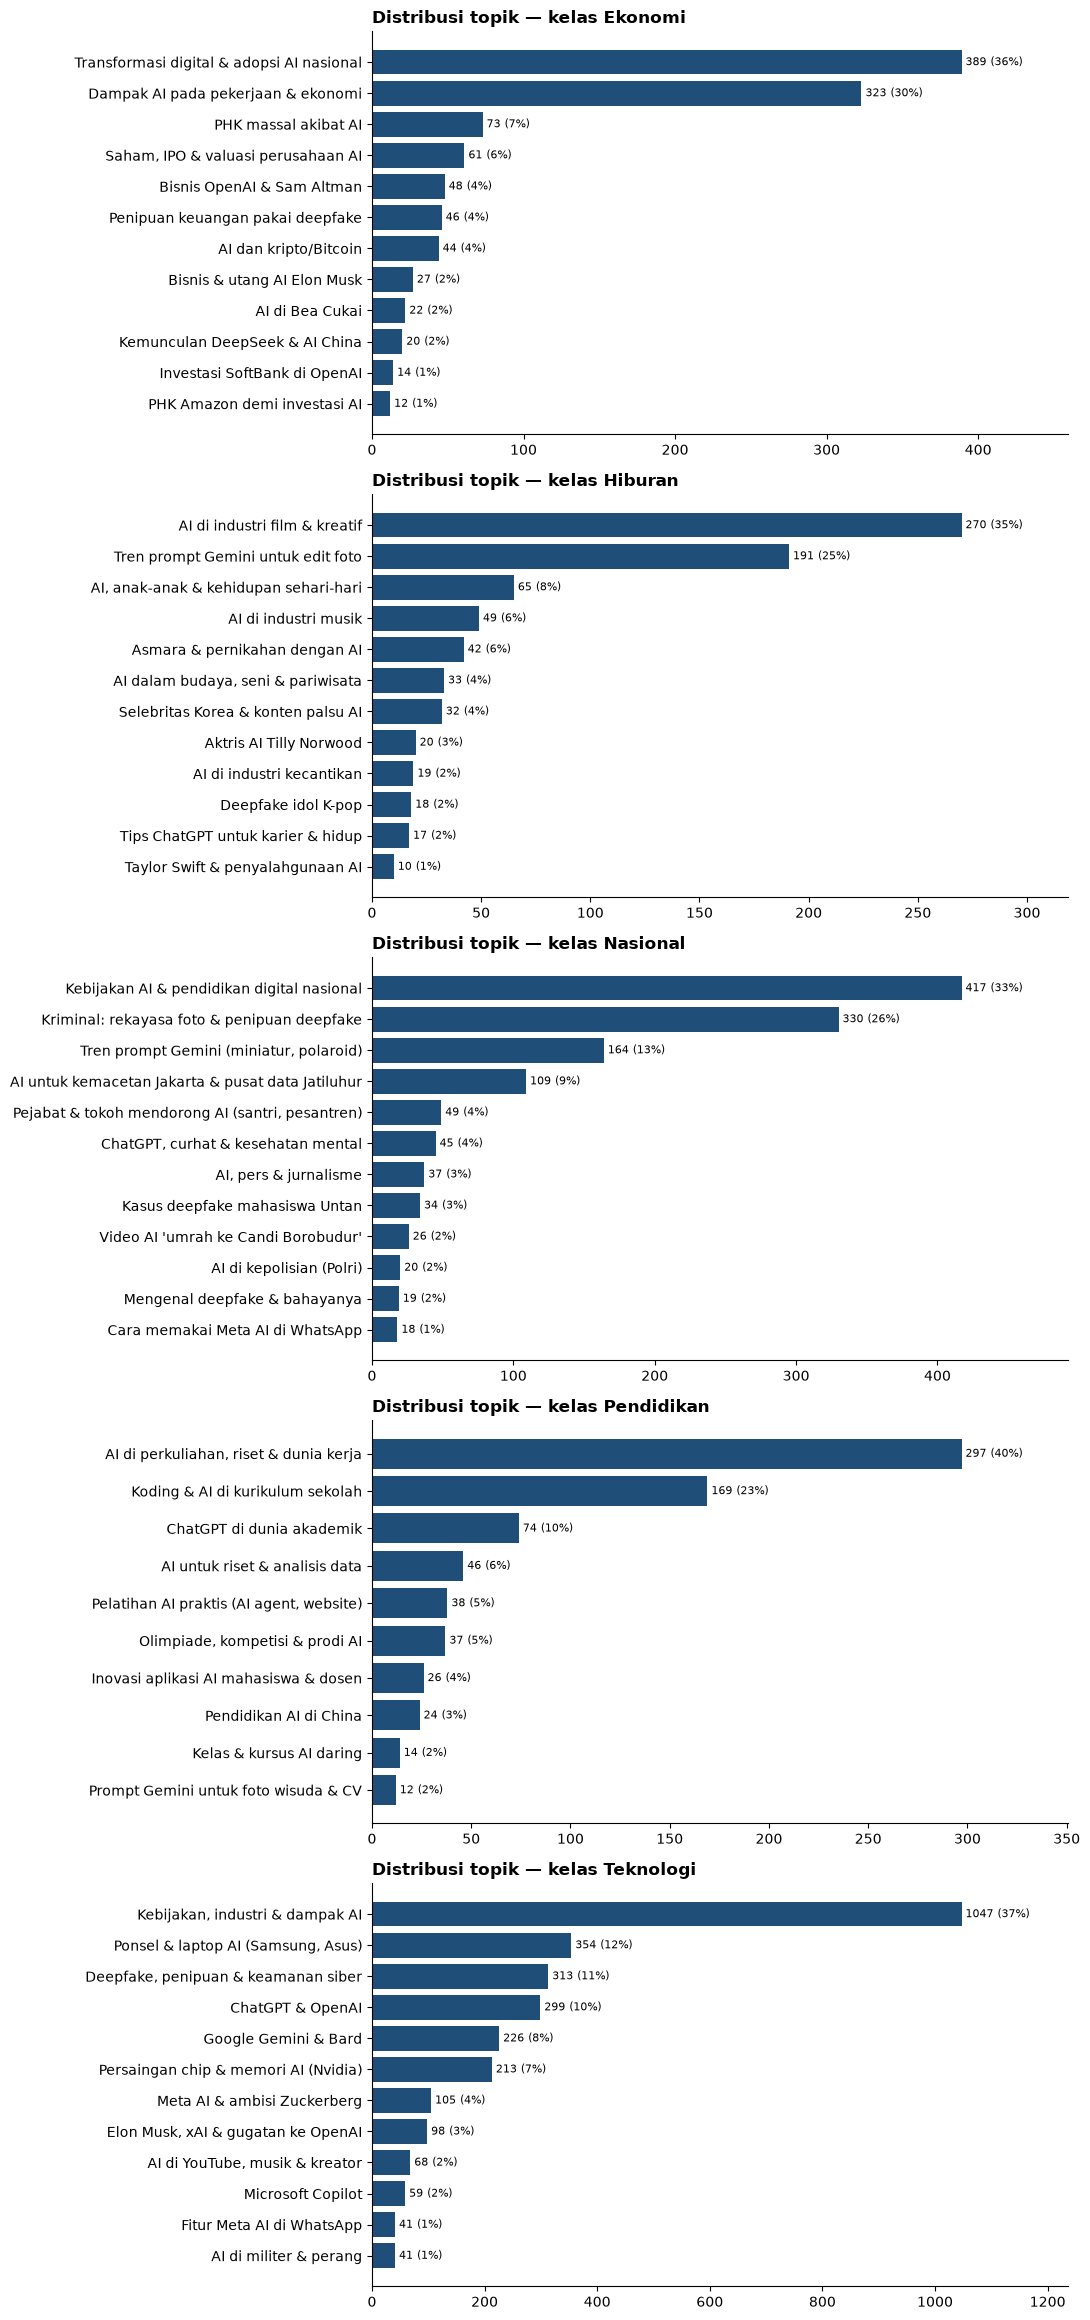

In [11]:
fig, axes = plt.subplots(len(CLASSES), 1, figsize=(11, 2.2 + 1.9 * len(CLASSES) + 0.2 * len(topic_info)))
for ax, cls in zip(axes, CLASSES):
    t = topic_info[topic_info.kelas == cls].sort_values("jumlah_dok")
    ax.barh(t.nama, t.jumlah_dok, color="#1f4e79")
    for y, (n, p) in enumerate(zip(t.jumlah_dok, t.proporsi)):
        ax.text(n, y, f" {n} ({p:.0%})", va="center", fontsize=8)
    ax.set_title(f"Distribusi topik — kelas {cls}", loc="left", fontweight="bold")
    ax.set_xlim(0, t.jumlah_dok.max() * 1.18); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(FIG / "04_topic_distribution.png", dpi=150); plt.show()

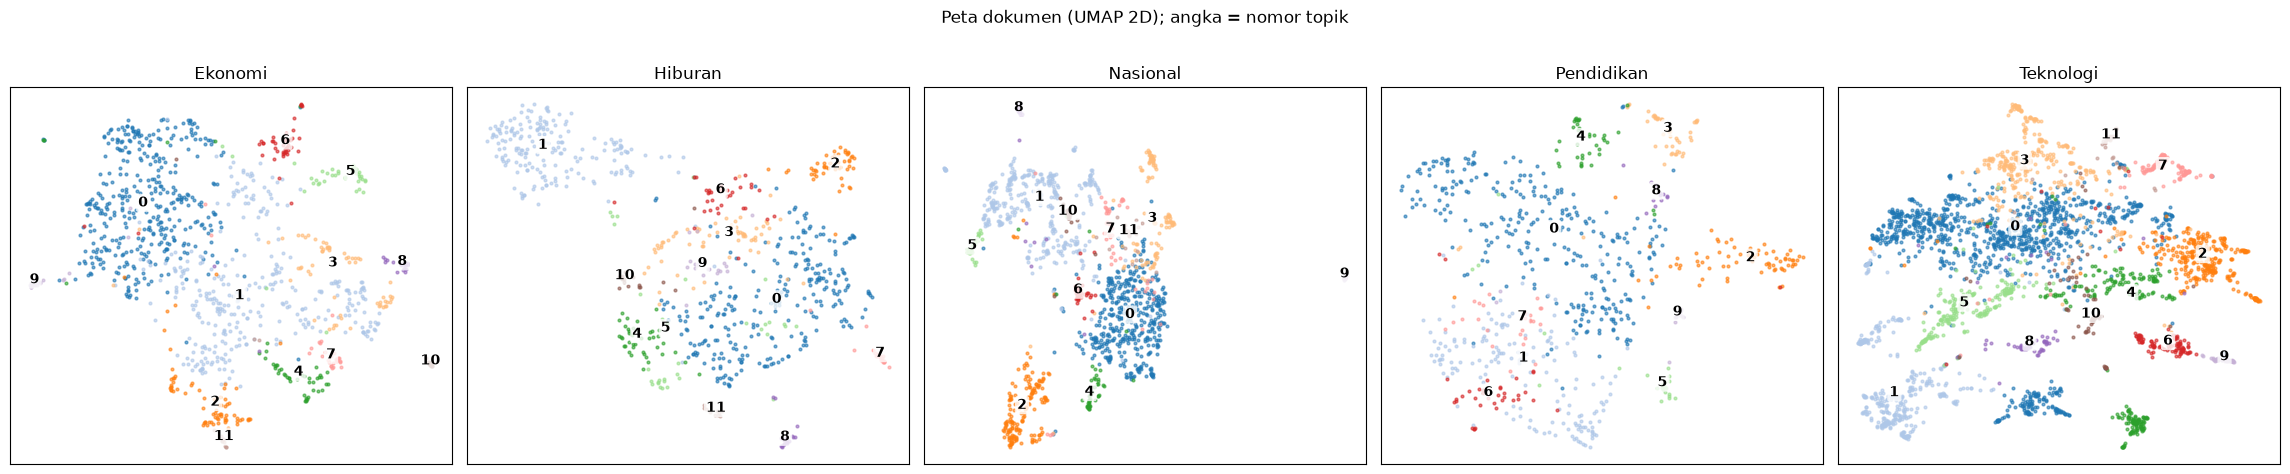

In [12]:
# Peta dokumen 2D (UMAP) per kelas, diwarnai menurut topik
fig, axes = plt.subplots(1, len(CLASSES), figsize=(4.6 * len(CLASSES), 4.6))
for ax, cls in zip(axes, CLASSES):
    R = results[cls]
    xy = UMAP(n_neighbors=15, n_components=2, min_dist=0.1, metric="cosine", random_state=SEED).fit_transform(R["emb"])
    pal = sns.color_palette("tab20", len(set(R["topics"])))
    for i, t in enumerate(sorted(set(R["topics"]))):
        mk = R["topics"] == t
        ax.scatter(xy[mk, 0], xy[mk, 1], s=4, color=pal[i], alpha=0.6)
        ax.text(*np.median(xy[mk], 0), str(t), fontsize=10, fontweight="bold", ha="center",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
    ax.set_title(cls); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Peta dokumen (UMAP 2D); angka = nomor topik", y=1.02)
plt.tight_layout(); plt.savefig(FIG / "04_umap_docs.png", dpi=150, bbox_inches="tight"); plt.show()

## 7. Dinamika topik dari waktu ke waktu

Prevalensi topik *c* pada kuartal *q* di dalam satu kelas: **P(c, q) = N(c, q) / N(q)**. Normalisasi
dengan N(q) penting karena volume berita AI sendiri berubah dari waktu ke waktu; yang ingin dilihat
adalah pergeseran **porsi perhatian**, bukan sekadar jumlah artikel.

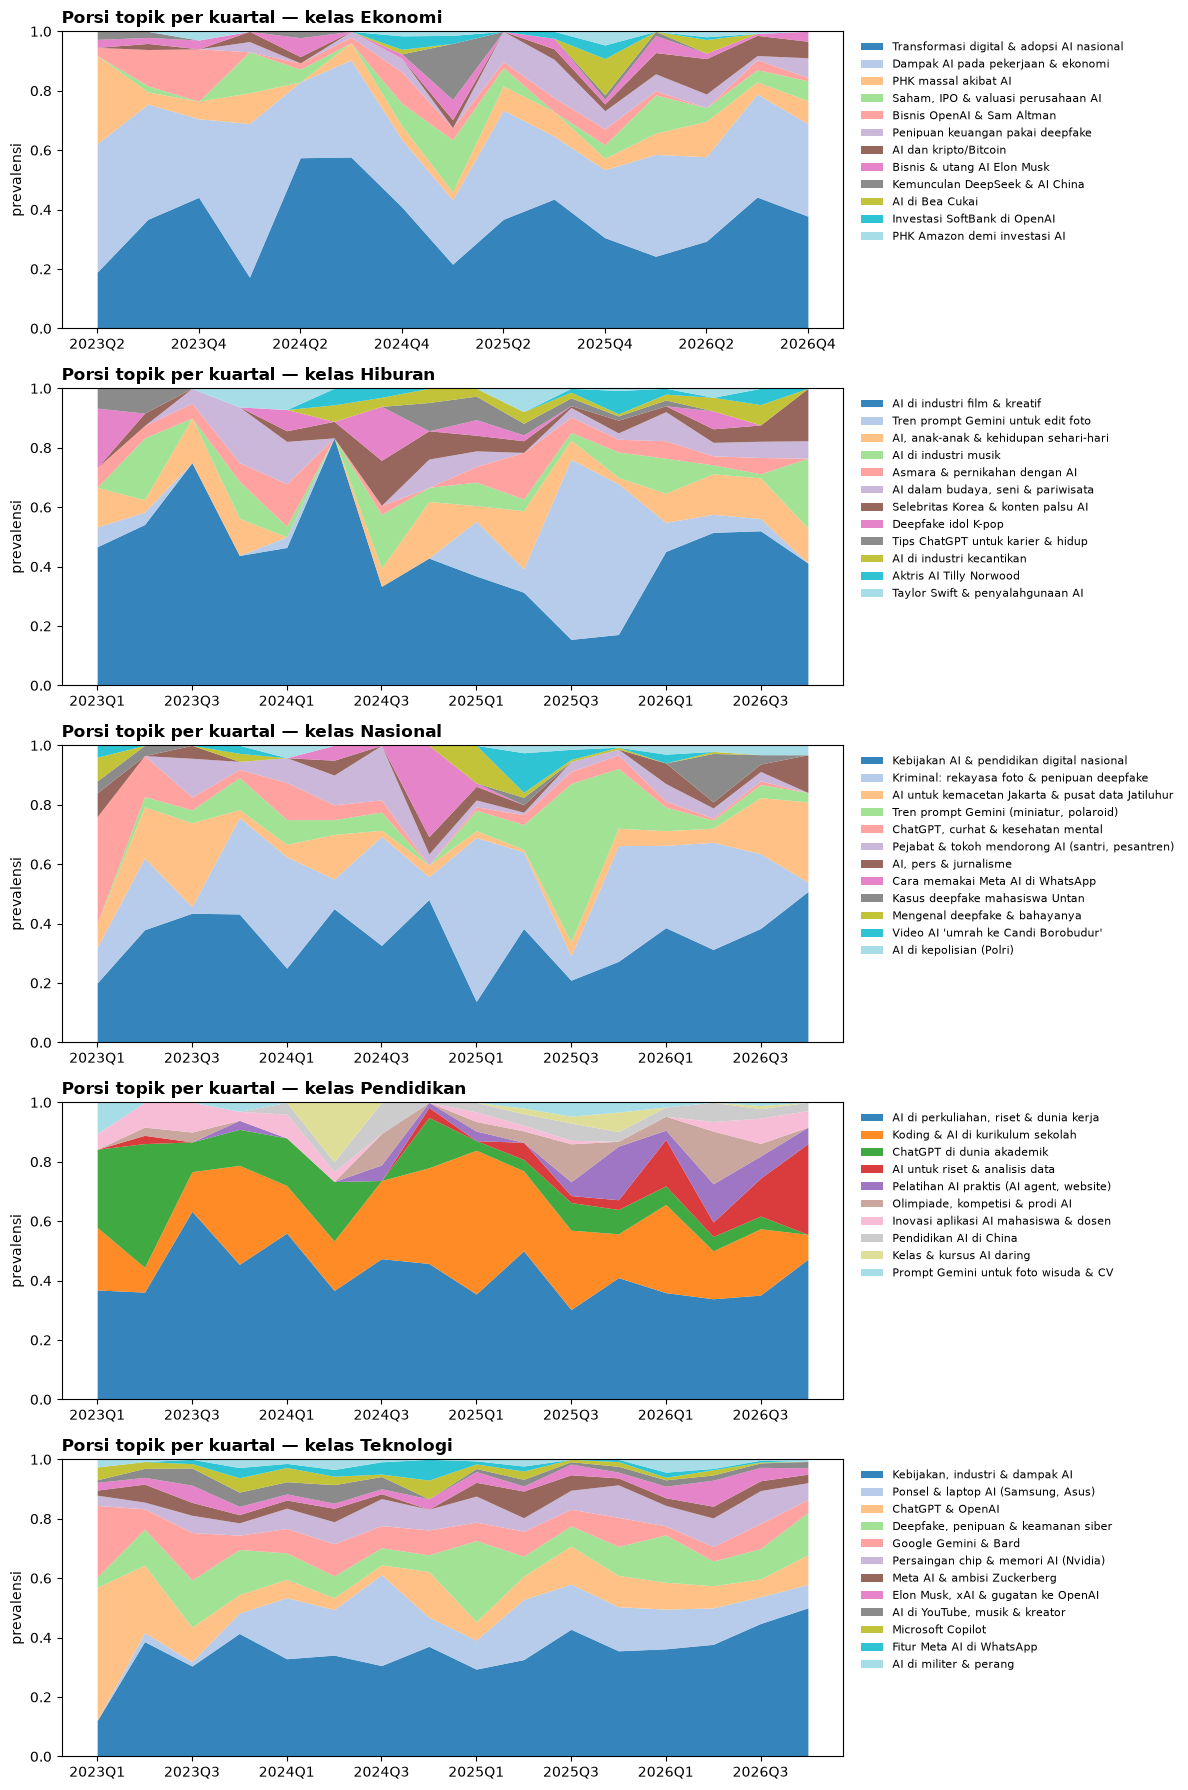

In [13]:
full = df.merge(doc_topics[["doc_id", "topic", "topic_name", "topic_sim"]], on="doc_id")
full["quarter"] = full["date"].dt.to_period("Q")
full.drop(columns=["quarter"]).to_csv(ROOT / "dataset_topics.csv", index=False, encoding="utf-8-sig")

fig, axes = plt.subplots(len(CLASSES), 1, figsize=(12, 3.6 * len(CLASSES)))
prev_tables = {}
for ax, cls in zip(axes, CLASSES):
    s = full[full.pred_label == cls]
    ct = pd.crosstab(s["quarter"], s["topic_name"])
    ct = ct[ct.sum(1) >= 15]                                # kuartal dengan dokumen terlalu sedikit dilewati
    prev = ct.div(ct.sum(1), axis=0)
    prev_tables[cls] = prev
    prev.index = prev.index.astype(str)
    prev[prev.mean().sort_values(ascending=False).index].plot.area(ax=ax, cmap="tab20", lw=0, alpha=0.9)
    ax.set_title(f"Porsi topik per kuartal — kelas {cls}", loc="left", fontweight="bold")
    ax.set_ylim(0, 1); ax.set_ylabel("prevalensi"); ax.set_xlabel("")
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(FIG / "04_topic_dynamics.png", dpi=150, bbox_inches="tight"); plt.show()

In [14]:
# Topik yang porsinya paling naik / turun: rata-rata 4 kuartal terakhir dikurangi 4 kuartal pertama
trend_rows = []
for cls, prev in prev_tables.items():
    if len(prev) < 8:
        continue
    delta = prev.tail(4).mean() - prev.head(4).mean()
    for name, d in delta.items():
        trend_rows.append({"kelas": cls, "topik": name, "awal": prev.head(4).mean()[name],
                           "akhir": prev.tail(4).mean()[name], "perubahan": d})
trend = pd.DataFrame(trend_rows).sort_values("perubahan")
trend.to_csv(RES / "topic_trend.csv", index=False)
print("Paling turun:"); display(trend.head(6).round(3))
print("Paling naik:"); display(trend.tail(6).iloc[::-1].round(3))

Paling turun:


,kelas,topik,awal,akhir,perubahan
38,Pendidikan,ChatGPT di dunia akademik,0.225,0.038,-0.187
28,Nasional,"ChatGPT, curhat & kesehatan mental",0.142,0.010,-0.132
48,Teknologi,ChatGPT & OpenAI,0.213,0.081,-0.132
4,Ekonomi,Dampak AI pada pekerjaan & ekonomi,0.401,0.321,-0.079
52,Teknologi,Google Gemini & Bard,0.129,0.051,-0.078
13,Hiburan,AI di industri film & kreatif,0.549,0.475,-0.074


Paling naik:


,kelas,topik,awal,akhir,perubahan
37,Pendidikan,AI untuk riset & analisis data,0.007,0.159,0.153
53,Teknologi,"Kebijakan, industri & dampak AI",0.306,0.422,0.115
57,Teknologi,"Ponsel & laptop AI (Samsung, Asus)",0.028,0.106,0.078
43,Pendidikan,"Pelatihan AI praktis (AI agent, website)",0.008,0.073,0.065
0,Ekonomi,AI dan kripto/Bitcoin,0.014,0.079,0.065
20,Hiburan,Selebritas Korea & konten palsu AI,0.010,0.074,0.064


**Interpretasi dinamika topik.** Prevalensi topik berubah jelas dan mengikuti peristiwa nyata:

- **Euforia ChatGPT memudar.** Di Teknologi, topik *ChatGPT & OpenAI* turun dari 21% (4 kuartal pertama)
  menjadi 8% (4 kuartal terakhir). Pola yang sama di kelas lain: *ChatGPT di dunia akademik* (Pendidikan)
  turun dari 23% menjadi 4%, *ChatGPT, curhat & kesehatan mental* (Nasional) dari 14% menjadi 1%, dan
  *Bisnis OpenAI & Sam Altman* (Ekonomi) dari 8% menjadi 2%. Pada 2023 ChatGPT adalah "AI" itu sendiri;
  setelahnya perhatian menyebar ke banyak produk dan isu.
- **AI menjadi fitur produk dan infrastruktur.** *Ponsel & laptop AI* naik dari 3% menjadi 11% sejak
  peluncuran Galaxy AI (awal 2024), dan *Persaingan chip & memori AI* dari 4% menjadi 8%.
- **AI menjadi urusan kebijakan dan industri.** *Kebijakan, industri & dampak AI* (Teknologi) naik dari
  31% menjadi 42%; *Transformasi digital & adopsi AI nasional* (Ekonomi) dari 29% menjadi 34%.
- **Sisi gelap AI menguat.** *Kriminal: rekayasa foto & penipuan deepfake* (Nasional) naik dari 18% menjadi
  23% (memuncak 2025), *Penipuan keuangan pakai deepfake* (Ekonomi) dari 1% menjadi 5%.
- **AI masuk ke praktik sehari-hari.** *AI untuk riset & analisis data* (Pendidikan) naik paling tajam,
  dari 1% menjadi 16%, dan *AI dan kripto* (Ekonomi) dari 1% menjadi 8%.
- **Lonjakan sesaat yang terkait peristiwa**: DeepSeek (Januari 2025), tren *prompt* foto Gemini
  (pertengahan–akhir 2025), Meta AI di WhatsApp (2024), dan video AI "umrah ke Candi Borobudur" (2025).

### Uji statistik: apakah distribusi topik berubah antar periode dan berbeda antar media?

Uji *chi-square* independensi antara topik dan (a) **periode** — P1: Des 2022–Des 2023 (adopsi awal
ChatGPT), P2: Jan 2024–Jun 2025, P3: Jul 2025–Okt 2026 — serta (b) **media**. *Cramér's V* dilaporkan
sebagai ukuran efek (0,1 kecil; 0,3 sedang; 0,5 besar), karena dengan ribuan dokumen nilai-p hampir
selalu sangat kecil.

In [15]:
def cramers_v(table):
    chi2, p, dof, _ = chi2_contingency(table)
    n = table.values.sum()
    return chi2, p, dof, np.sqrt(chi2 / (n * (min(table.shape) - 1)))


full["period"] = pd.cut(full["date"], [pd.Timestamp("2022-11-01"), pd.Timestamp("2024-01-01"),
                                       pd.Timestamp("2025-07-01"), pd.Timestamp("2026-12-01")],
                        labels=["P1 (2022-12..2023-12)", "P2 (2024-01..2025-06)", "P3 (2025-07..2026-10)"], right=False)
test_rows = []
for cls in CLASSES:
    s = full[full.pred_label == cls]
    for var in ("period", "source"):
        tab = pd.crosstab(s["topic_name"], s[var])
        tab = tab.loc[:, tab.sum() > 0]
        if tab.shape[1] < 2:
            continue
        chi2, p, dof, v = cramers_v(tab)
        test_rows.append({"kelas": cls, "variabel": var, "chi2": round(chi2, 1), "dof": dof, "p_value": p, "cramers_v": round(v, 3)})
tests = pd.DataFrame(test_rows)
tests.to_csv(RES / "topic_chi2_tests.csv", index=False)
tests

,kelas,variabel,chi2,dof,p_value,cramers_v
0,Ekonomi,period,107.1,22,3.620540e-13,0.223
1,Ekonomi,source,150.2,22,4.306035e-21,0.264
2,Hiburan,period,123.3,22,4.421276e-16,0.284
3,Hiburan,source,480.0,22,1.055656e-87,0.560
4,Nasional,period,183.2,22,2.080046e-27,0.269
5,Nasional,source,76.5,22,5.943731e-08,0.174
6,Pendidikan,period,100.2,18,2.020119e-13,0.261
7,Pendidikan,source,12.7,18,8.078901e-01,0.093
8,Teknologi,period,207.2,22,4.321706e-32,0.190
9,Teknologi,source,266.4,22,7.292500e-44,0.216


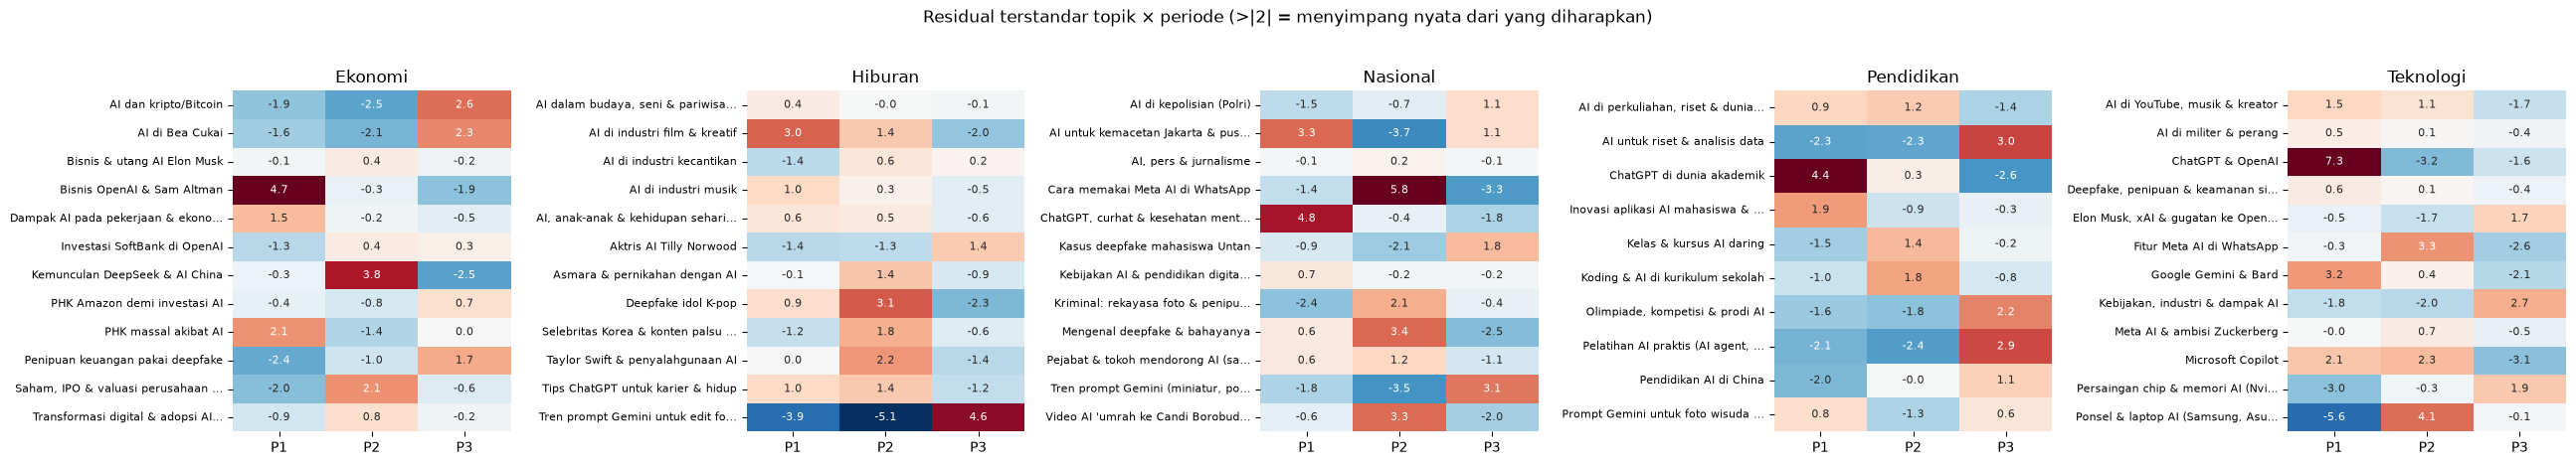

In [16]:
# Residual terstandar topik x periode: sel merah = topik lebih banyak dari yang diharapkan pada periode itu
fig, axes = plt.subplots(1, len(CLASSES), figsize=(5.2 * len(CLASSES), 4.5))
for ax, cls in zip(axes, CLASSES):
    s = full[full.pred_label == cls]
    tab = pd.crosstab(s["topic_name"], s["period"])
    exp = chi2_contingency(tab)[3]
    resid = (tab - exp) / np.sqrt(exp)
    resid.columns = ["P1", "P2", "P3"][:resid.shape[1]]
    resid.index = [n if len(n) < 34 else n[:32] + "…" for n in resid.index]
    sns.heatmap(resid, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=ax, cbar=False, annot_kws={"size": 8})
    ax.set_title(cls); ax.set_ylabel(""); ax.tick_params(axis="y", labelsize=8)
plt.suptitle("Residual terstandar topik × periode (>|2| = menyimpang nyata dari yang diharapkan)", y=1.03)
plt.tight_layout(); plt.savefig(FIG / "04_period_residuals.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretasi uji statistik.** Distribusi topik **berbeda signifikan antar-periode di kelima kelas**
(p < 0,001). Ukuran efeknya kecil–sedang (Cramér's V 0,19–0,28). Residual terstandar menguatkan pola di
atas: *ChatGPT & OpenAI* sangat berlebih di P1 (residual +7,3), begitu pula *ChatGPT, curhat & kesehatan
mental* (+4,8), *Bisnis OpenAI & Sam Altman* (+4,7), dan *ChatGPT di dunia akademik* (+4,4); *Meta AI di
WhatsApp* (+5,8), *Ponsel & laptop AI* (+4,1), dan *DeepSeek* (+3,8) berlebih di P2; *tren prompt Gemini*
(+4,6) berlebih di P3.

Antar-media, distribusi topik juga berbeda signifikan di empat kelas (kecuali Pendidikan, p = 0,81, karena
hampir seluruh artikelnya dari Detik). Efek terbesar ada di **Hiburan** (V = 0,56): **72%** artikel AI
di kanal hiburan Liputan6 adalah *tren prompt Gemini untuk edit foto*, sedangkan di Detik (49%) dan CNN
(44%) topik terbesarnya *AI di industri film & kreatif*; CNN juga lebih banyak membahas *AI, anak-anak &
kehidupan sehari-hari* (21%). Jadi selain *kapan*, *siapa medianya* juga ikut menentukan isu AI yang
diangkat — satu portal memperlakukan AI sebagai konten tutorial viral, portal lain sebagai isu industri.

### Pergeseran kosakata di dalam topik (`topics_over_time`)

Untuk topik terbesar tiap kelas, c-TF-IDF dihitung ulang per tahun. Ini memperlihatkan bagaimana
**isi** sebuah topik berubah walaupun topiknya sama (misalnya dari satu produk ke produk lain).

In [17]:
tot_rows = []
for cls in CLASSES:
    R = results[cls]
    # timestamp diberikan sebagai datetime (bukan string) agar kompatibel dengan pandas 3
    years = [pd.Timestamp(y, 1, 1).to_pydatetime() for y in R["sub"]["date"].dt.year]
    tot = R["model"].topics_over_time(R["docs_tok"], years, topics=list(R["topics"]),
                                      global_tuning=True, evolution_tuning=False)
    top2 = pd.Series(R["topics"]).value_counts().index[:2]
    for t in top2:
        for _, r in tot[tot.Topic == t].sort_values("Timestamp").iterrows():
            tot_rows.append({"kelas": cls, "topik": TOPIC_NAMES.get((cls, t), f"Topik {t}"),
                             "tahun": str(r.Timestamp)[:4], "dok": r.Frequency, "kata_kunci_tahun_itu": r.Words})
tot_df = pd.DataFrame(tot_rows)
tot_df.to_csv(RES / "topics_over_time_words.csv", index=False)
tot_df

,kelas,topik,tahun,dok,kata_kunci_tahun_itu
0,Ekonomi,Transformasi digital & adopsi AI nasional,2023,41,"digital, golden_visa, platform, data, sistem"
1,Ekonomi,Transformasi digital & adopsi AI nasional,2024,89,"bri, nasabah, digital, sabrina, layanan"
2,Ekonomi,Transformasi digital & adopsi AI nasional,2025,111,"telkom, digital, industri, nasional, kolaborasi"
3,Ekonomi,Transformasi digital & adopsi AI nasional,2026,148,"digital, nasional, data_center, pemerintah, pengembangan"
4,Ekonomi,Dampak AI pada pekerjaan & ekonomi,2023,48,"pekerjaan, manusia, membantu, pekerja, jalan"
5,Ekonomi,Dampak AI pada pekerjaan & ekonomi,2024,59,"bisnis, membantu, pekerjaan, penggunaan, bank"
6,Ekonomi,Dampak AI pada pekerjaan & ekonomi,2025,82,"kekayaan, pekerjaan, manusia, chip, kerja"
7,Ekonomi,Dampak AI pada pekerjaan & ekonomi,2026,134,"miliarder, kekayaan, negara, kategori, pekerjaan"
8,Hiburan,AI di industri film & kreatif,2023,42,"iklan, film, aktor, deepfake, model"
9,Hiburan,AI di industri film & kreatif,2024,48,"model, film, miss, robot, iklan"


**Interpretasi pergeseran kosakata.** Topik yang sama berubah isinya dari tahun ke tahun. *Kriminal:
rekayasa foto & penipuan deepfake* (Nasional) pada 2023 dikaitkan dengan **pemilu, kampanye, dan hoaks**,
pada 2024 dengan kasus rekayasa yang ditangani polres, dan pada 2025 dengan kasus tersangka tertentu
(misalnya kasus "Chiko"). *Transformasi digital & adopsi AI nasional* (Ekonomi) bergeser dari BRI dan
layanan nasabah (2024) ke Telkom (2025) dan *data center* serta peran pemerintah (2026). *Koding & AI di
kurikulum sekolah* (Pendidikan) bergeser dari program pelatihan seperti Bangkit (2023–2024) ke kebijakan
mata pelajaran koding-AI oleh Kemendikdasmen (2025). `topics_over_time` dengan demikian menangkap bukan
hanya *berapa banyak* sebuah topik dibahas, tetapi juga *bagaimana* topik itu dibahas.

## Ringkasan Task 4

BERTopic dijalankan terpisah pada lima kelas hasil klasifikasi IndoBERT dan menghasilkan 58 topik yang
koheren (C_v rata-rata 0,62, lebih tinggi dari LDA di semua kelas) dan beragam (diversity 0,94). Setiap
topik memiliki kata kunci, nama, dokumen representatif, dan prevalensi per kuartal. Analisis dinamika
menunjukkan pergeseran pemberitaan AI Indonesia dari euforia ChatGPT (2023) ke AI sebagai fitur produk,
urusan kebijakan dan industri, alat sehari-hari, serta ancaman kriminal (2025–2026); pergeseran ini
signifikan secara statistik di semua kelas.